# COU 07506 — Digital Signal Processing
## Week 4: z-Transform Laboratory — Poles, Zeros and Stability

**Name:** IBRAHIM KELVIN SHIJA

**Registration Number:** 240242495885

**Date:** 23/11/2026


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

plt.rcParams["figure.figsize"] = (9, 3.5)

In [1]:
def zplane(b, a, ax=None):
    z, p, k = signal.tf2zpk(b, a)

    ax = ax or plt.gca()

    th = np.linspace(0, 2*np.pi, 400)

    ax.plot(np.cos(th), np.sin(th), "k--", lw=0.8)
    ax.plot(z.real, z.imag, "o", mfc="none", ms=9, label="zeros")
    ax.plot(p.real, p.imag, "x", ms=9, mew=2, label="poles")

    ax.set_aspect("equal")
    ax.legend()
    ax.set_xlabel("Re")
    ax.set_ylabel("Im")

    return z, p

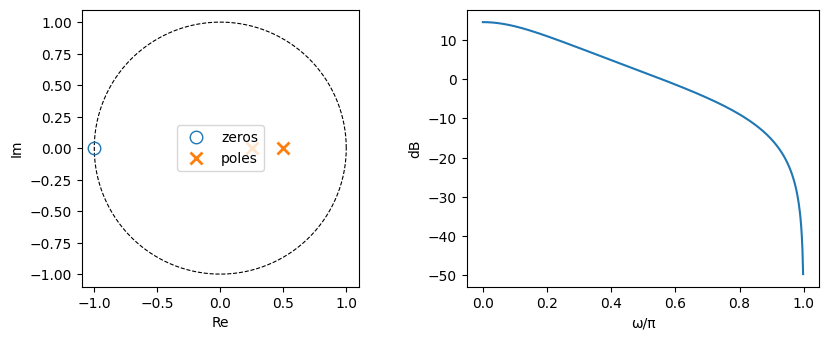

poles: [0.5  0.25]  stable: True


In [4]:
b, a = [1, 1], [1, -0.75, 0.125]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))

z, p = zplane(b, a, ax1)

w, H = signal.freqz(b, a, worN=512)

ax2.plot(w/np.pi, 20*np.log10(np.abs(H)))
ax2.set_xlabel("ω/π")
ax2.set_ylabel("dB")

plt.show()

print("poles:", p, " stable:", np.all(np.abs(p) < 1))

### Observation

The pole-zero plot shows one zero at z = -1 and two poles at z = 0.5 and z = 0.25. Both poles lie inside the unit circle. Therefore, the system is stable.

The frequency response shows that the magnitude decreases as the normalized frequency increases, indicating low-pass filter behaviour.

In [ ]:
## Task 4.2 — Inverse z-transform with residuez

In [5]:
r, p, k = signal.residuez([1], [1, -0.75, 0.125])

print("Residues:", r)
print("Poles:", p)
print("Direct term:", k)

Residues: [-1.  2.]
Poles: [0.25 0.5 ]
Direct term: []


In [6]:
n = np.arange(10)

x_pf = sum(ri * pi**n for ri, pi in zip(r, p)).real

impulse = np.zeros(10)
impulse[0] = 1

x_lf = signal.lfilter(
    [1],
    [1, -0.75, 0.125],
    impulse
)

print("Using residuez:", x_pf)
print("Using lfilter:", x_lf)
print("Both methods agree:", np.allclose(x_pf, x_lf))

Using residuez: [1.         0.75       0.4375     0.234375   0.12109375 0.06152344
 0.03100586 0.01556396 0.00779724 0.00390244]
Using lfilter: [1.         0.75       0.4375     0.234375   0.12109375 0.06152344
 0.03100586 0.01556396 0.00779724 0.00390244]
Both methods agree: True


In [7]:
r2, p2, k2 = signal.residuez(
    [1, 1],
    [1, -0.75, 0.125]
)

print("Residues:", r2)
print("Poles:", p2)
print("Direct term:", k2)

Residues: [-5.  6.]
Poles: [0.25 0.5 ]
Direct term: []


In [8]:
n = np.arange(10)

h_formula = 6*(0.5**n) - 5*(0.25**n)

impulse = np.zeros(10)
impulse[0] = 1

h_lfilter = signal.lfilter(
    [1, 1],
    [1, -0.75, 0.125],
    impulse
)

print("Using formula:", h_formula)
print("Using lfilter:", h_lfilter)
print("Both methods agree:", np.allclose(h_formula, h_lfilter))

Using formula: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Using lfilter: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Both methods agree: True


### Observation

The residuez() function was used to obtain the residues and poles of the system. The inverse z-transform produced the impulse response:

h(n) = 6(0.5)^n - 5(0.25)^n

The result was verified using signal.lfilter(). Both methods produced identical impulse responses, confirming that the partial fraction expansion was correct.

In [9]:
r_values = [0.5, 0.8, 0.95, 1.0, 1.05]

theta = np.pi / 4

for r in r_values:
    b = [1]
    a = [1, -2*r*np.cos(theta), r**2]

    print(f"r = {r}")
    print("Denominator coefficients:", a)
    print("Poles:", np.roots(a))
    print("Stable:", np.all(np.abs(np.roots(a)) < 1))
    print()

r = 0.5
Denominator coefficients: [1, np.float64(-0.7071067811865476), 0.25]
Poles: [0.35355339+0.35355339j 0.35355339-0.35355339j]
Stable: True

r = 0.8
Denominator coefficients: [1, np.float64(-1.1313708498984762), 0.6400000000000001]
Poles: [0.56568542+0.56568542j 0.56568542-0.56568542j]
Stable: True

r = 0.95
Denominator coefficients: [1, np.float64(-1.3435028842544403), 0.9025]
Poles: [0.67175144+0.67175144j 0.67175144-0.67175144j]
Stable: True

r = 1.0
Denominator coefficients: [1, np.float64(-1.4142135623730951), 1.0]
Poles: [0.70710678+0.70710678j 0.70710678-0.70710678j]
Stable: False

r = 1.05
Denominator coefficients: [1, np.float64(-1.48492424049175), 1.1025]
Poles: [0.74246212+0.74246212j 0.74246212-0.74246212j]
Stable: False



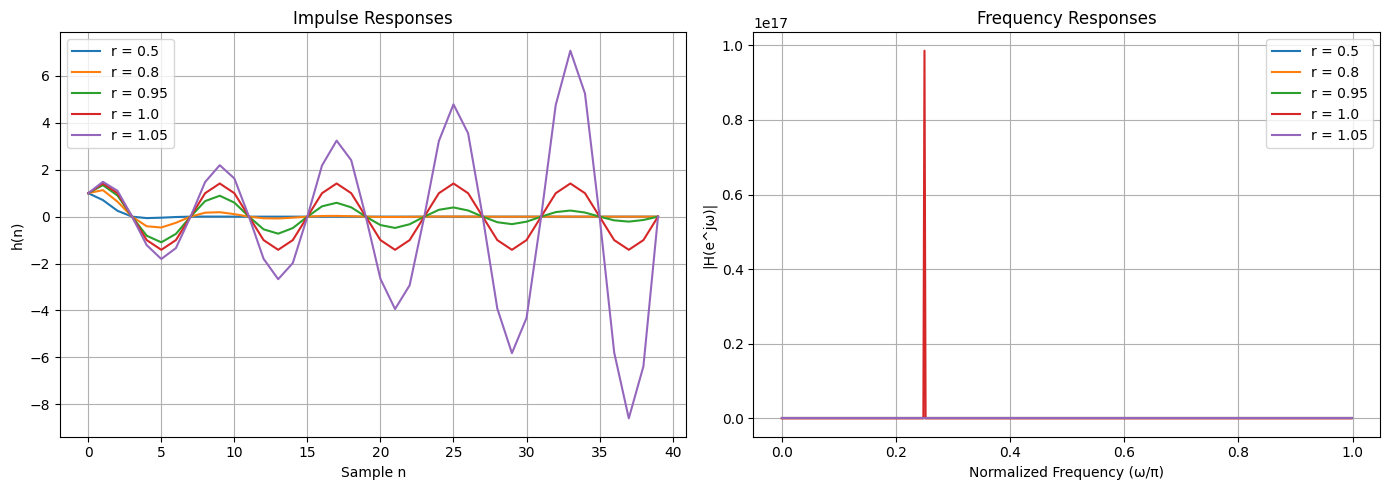

In [10]:
r_values = [0.5, 0.8, 0.95, 1.0, 1.05]

theta = np.pi / 4

n = np.arange(40)
impulse = np.zeros(40)
impulse[0] = 1

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

for r in r_values:
    b = [1]
    a = [1, -2*r*np.cos(theta), r**2]

    # Impulse response
    h = signal.lfilter(b, a, impulse)
    ax1.plot(n, h, label=f"r = {r}")

    # Frequency response
    w, H = signal.freqz(b, a, worN=512)
    ax2.plot(w/np.pi, np.abs(H), label=f"r = {r}")

ax1.set_title("Impulse Responses")
ax1.set_xlabel("Sample n")
ax1.set_ylabel("h(n)")
ax1.legend()
ax1.grid()

ax2.set_title("Frequency Responses")
ax2.set_xlabel("Normalized Frequency (ω/π)")
ax2.set_ylabel("|H(e^jω)|")
ax2.legend()
ax2.grid()

plt.tight_layout()
plt.show()

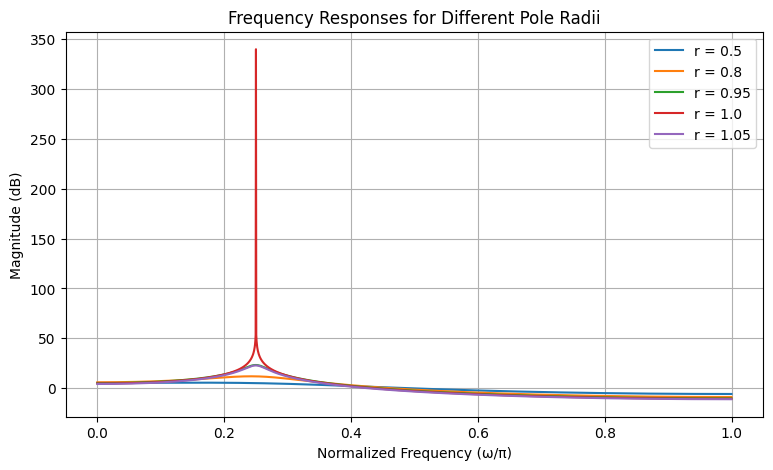

In [11]:
r_values = [0.5, 0.8, 0.95, 1.0, 1.05]
theta = np.pi / 4

plt.figure(figsize=(9, 5))

for r in r_values:
    b = [1]
    a = [1, -2*r*np.cos(theta), r**2]

    w, H = signal.freqz(b, a, worN=2048)

    magnitude_db = 20 * np.log10(np.maximum(np.abs(H), 1e-12))

    plt.plot(w/np.pi, magnitude_db, label=f"r = {r}")

plt.title("Frequency Responses for Different Pole Radii")
plt.xlabel("Normalized Frequency (ω/π)")
plt.ylabel("Magnitude (dB)")
plt.legend()
plt.grid()
plt.show()

### Observation

The impulse response shows that as the pole radius (r) increases towards 1, the oscillations decay more slowly. For r = 0.5, the response decays quickly, while for r = 0.95, the oscillations last longer. At r = 1.0, the oscillations continue without decaying. At r = 1.05, the amplitude increases with time.

The frequency response shows that the resonance peak becomes sharper and higher as r approaches 1. This indicates a narrower bandwidth. When r = 1.0, the theoretical magnitude becomes infinite at the resonant frequency.

### Stability

The systems with r = 0.5, 0.8 and 0.95 are stable because their poles are inside the unit circle. The systems with r = 1.0 and r = 1.05 are unstable because their poles are not strictly inside the unit circle.

H1
Zeros: []
Poles: [0.8+0.5j 0.8-0.5j]
Stable: True

H2
Zeros: [-1.]
Poles: [2.  0.5]
Stable: False

H3
Zeros: []
Poles: [-1.   0.5]
Stable: False

H4
Zeros: [-1.00000000e+00+0.j  8.32667268e-17+1.j  8.32667268e-17-1.j
  1.00000000e+00+0.j]
Poles: []
Stable: True



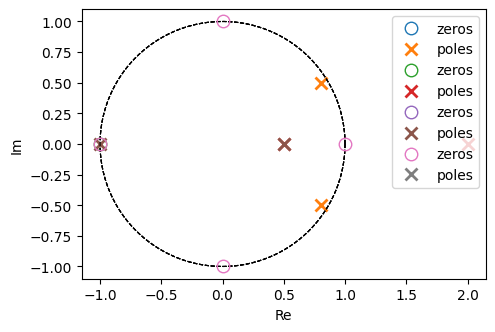

In [12]:
systems = {
    "H1": ([1], [1, -1.6, 0.89]),
    "H2": ([1, 1], [1, -2.5, 1]),
    "H3": ([1], [1, 0.5, -0.5]),
    "H4": ([1, 0, 0, 0, -1], [1])
}

for name, (b, a) in systems.items():
    z, p = zplane(b, a)

    stable = np.all(np.abs(p) < 1)

    print(name)
    print("Zeros:", z)
    print("Poles:", p)
    print("Stable:", stable)
    print()

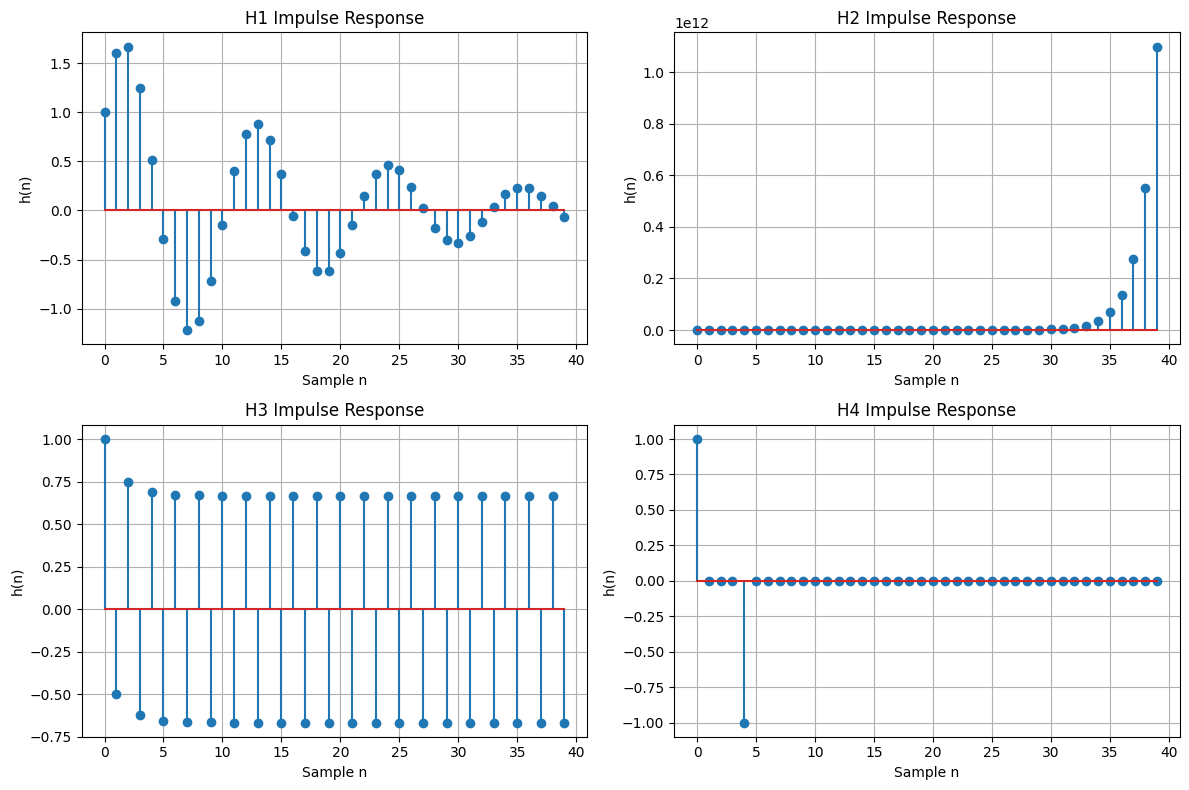

In [13]:
n = np.arange(40)

impulse = np.zeros(40)
impulse[0] = 1

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (name, (b, a)) in zip(axes.flat, systems.items()):
    h = signal.lfilter(b, a, impulse)

    ax.stem(n, h)
    ax.set_title(f"{name} Impulse Response")
    ax.set_xlabel("Sample n")
    ax.set_ylabel("h(n)")
    ax.grid()

plt.tight_layout()
plt.show()

### Observation

The pole-zero analysis and impulse response plots were used to classify the four systems.

- H1 is stable because all its poles are inside the unit circle. Its impulse response decays with time.
- H2 is unstable because it has a pole outside the unit circle. Its impulse response grows with time.
- H3 is unstable because one pole lies exactly on the unit circle. Its impulse response does not decay to zero.
- H4 is stable because it is an FIR system with a finite-duration impulse response.

The results confirm that pole locations determine the stability of a causal system.

In [15]:
fs = 8000
f0 = 1000
r = 0.97

theta = 2 * np.pi * f0 / fs

b = [1, 0, -1]
a = [1, -2*r*np.cos(theta), r**2]

print("Numerator coefficients:", b)
print("Denominator coefficients:", a)

z, p, k = signal.tf2zpk(b, a)

print("Zeros:", z)
print("Poles:", p)
print("Pole radii:", np.abs(p))
print("Stable:", np.all(np.abs(p) < 1))

Numerator coefficients: [1, 0, -1]
Denominator coefficients: [1, np.float64(-1.3717871555019023), 0.9409]
Zeros: [-1.  1.]
Poles: [0.68589358+0.68589358j 0.68589358-0.68589358j]
Pole radii: [0.97 0.97]
Stable: True


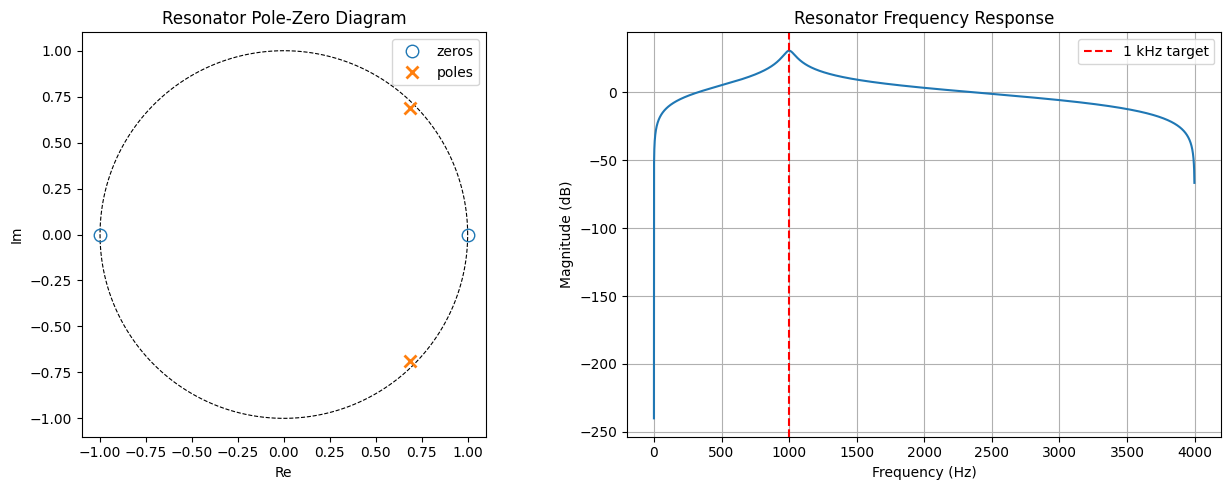

Peak frequency: 1000.9765625 Hz


In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Pole-zero diagram
z, p = zplane(b, a, ax1)
ax1.set_title("Resonator Pole-Zero Diagram")

# Frequency response
w, H = signal.freqz(b, a, worN=4096, fs=fs)

ax2.plot(w, 20*np.log10(np.maximum(np.abs(H), 1e-12)))
ax2.axvline(f0, color="red", linestyle="--", label="1 kHz target")
ax2.set_title("Resonator Frequency Response")
ax2.set_xlabel("Frequency (Hz)")
ax2.set_ylabel("Magnitude (dB)")
ax2.legend()
ax2.grid()

plt.tight_layout()
plt.show()

peak_index = np.argmax(np.abs(H))
print("Peak frequency:", w[peak_index], "Hz")

In [17]:
rng = np.random.default_rng(0)

# Generate 2 seconds of white noise
x = rng.standard_normal(fs * 2)

# Apply the resonator
y = signal.lfilter(b, a, x)

In [18]:
from IPython.display import Audio, display

display(Audio(y, rate=fs))

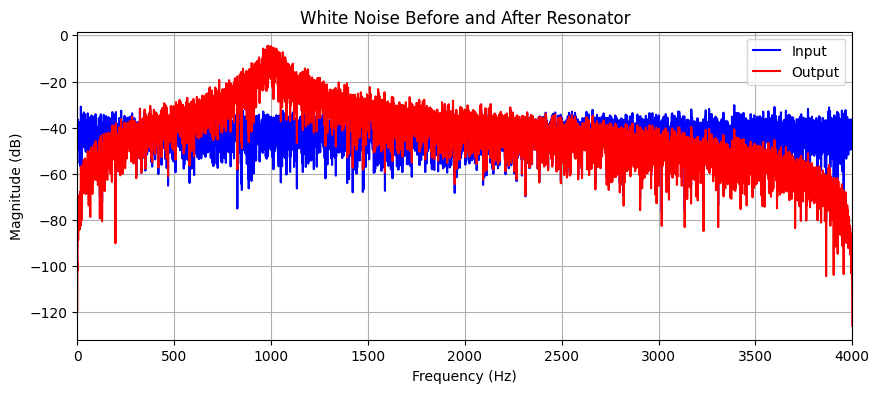

In [19]:
fig, ax = plt.subplots(figsize=(10, 4))

ax.magnitude_spectrum(x, Fs=fs, scale='dB',
                      color='blue', label='Input')
ax.magnitude_spectrum(y, Fs=fs, scale='dB',
                      color='red', label='Output')

ax.set_title("White Noise Before and After Resonator")
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Magnitude (dB)")
ax.set_xlim(0, fs/2)
ax.legend()
ax.grid()

plt.show()

In [ ]:
### Observation

The pole-zero plot shows two zeros at z = +1 and z = -1, and two complex conjugate poles with a radius of 0.97. Since both poles are inside the unit circle, the resonator is stable.

The frequency response has a resonance peak around 1 kHz, which is the target frequency. The zeros at z = +1 and z = -1 attenuate the DC and Nyquist frequencies, respectively.

When white noise is passed through the resonator, the output spectrum shows increased magnitude around 1 kHz. This confirms that the resonator emphasizes frequencies near its designed resonant frequency.

## Checkpoint 4

The stability of the four systems was classified using their pole locations and impulse responses.

- H1: Stable
- H2: Unstable
- H3: Unstable
- H4: Stable

The resonator designed in Task 4.5 has a resonance peak around 1 kHz. Its poles are inside the unit circle, confirming that the resonator is stable.

The required pole-zero plots, impulse response plots and frequency response are shown in the preceding tasks.

### Analysis Question 1

As the pole radius (r) increases towards 1, the resonance peak becomes sharper and higher, while the bandwidth becomes narrower.

When r is small, the resonance peak is wider, meaning the bandwidth is larger. When r approaches 1, the filter becomes more selective around its resonant frequency, resulting in a narrower bandwidth.

### Analysis Question 2

When a pole lies exactly on the unit circle, the impulse response does not decay to zero. For a complex conjugate pole pair, the impulse response produces continuous oscillations with constant amplitude.

Therefore, the system is not BIBO stable because the pole is not strictly inside the unit circle.

### Analysis Question 3

The zero at z = +1 blocks the DC frequency (0 Hz), while the zero at z = -1 blocks the Nyquist frequency (4000 Hz).

These zeros attenuate the low-frequency and high-frequency ends of the spectrum. The resonator poles emphasize frequencies around 1 kHz, resulting in a band-pass response.

### Analysis Question 4

The stability triangle was used to check the second-order systems in Task 4.4.

For a second-order system with denominator:

A(z) = 1 + a1*z^(-1) + a2*z^(-2)

The stability conditions are:

1. |a2| < 1
2. 1 + a1 + a2 > 0
3. 1 - a1 + a2 > 0

The results are:

- H1: All three conditions are satisfied. Therefore, H1 is stable.
- H2: The first and second conditions are not satisfied. Therefore, H2 is unstable.
- H3: The third condition is not satisfied because its value is zero. Therefore, H3 is unstable.

These results agree with the pole-zero analysis in Task 4.4.